# Machine Learning–Driven Classification of IoT Network Attacks Using RT-IoT2022
### Model: Random Forest Classifier

**Student:** M Aditya  **ID:** E0224002  **Course:** B.Tech Cybersecurity & IoT, Machine Learning (Sem 5)

---
**Aim:** Build a Machine-Learning-based **Intrusion Detection System (IDS)** that looks at IoT network traffic and classifies each flow as **Normal** or one of **9 attack types**, using a **Random Forest** classifier.

**Steps:**
`1. Import libraries → 2. Load dataset → 3. Understand data → 4. EDA → 5. Preprocessing → 6. Train Random Forest → 7. Evaluate → 8. Cross-validation → 9. Feature importance → 10. Save model & predict`

## 1. Import libraries
- **pandas / numpy**: handle the data table
- **matplotlib / seaborn**: draw graphs
- **scikit-learn**: Random Forest model, train/test split, evaluation metrics
- **joblib**: save the trained model

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)

from ids_utils import TARGET, NORMAL_CLASSES, CATEGORY_MAP, to_binary, basic_clean, encode

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load the dataset
**RT-IoT2022** (UCI Machine Learning Repository) contains real network traffic from IoT devices (ThingSpeak LED, Wipro smart bulb, MQTT sensor) while attackers ran real tools (Nmap, Hping3, Metasploit, Slowloris, ARP spoofing).
Each **row = one network flow**, each **column = one measurement** of that flow, and `Attack_type` is the label we predict.

In [2]:
DATA_PATH = "data/RT_IOT2022.csv"
if not os.path.exists(DATA_PATH):              # download automatically if the file is missing
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=942)
    pd.concat([ds.data.features, ds.data.targets], axis=1).to_csv(DATA_PATH, index=False)

df = pd.read_csv(DATA_PATH)
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (123117, 85)


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,...,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,...,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,...,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,...,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,...,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,...,0.0,2.981470e+07,2.981470e+07,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish


## 3. Understand the data

In [3]:
print("Rows            :", df.shape[0])
print("Columns         :", df.shape[1], "(83 features + 1 target + 1 index column)")
print("Missing values  :", df.isnull().sum().sum())
print("Duplicate rows  :", df.duplicated().sum())
print("\nColumn data types:\n", df.dtypes.value_counts(), sep="")

Rows            : 123117
Columns         : 85 (83 features + 1 target + 1 index column)
Missing values  : 0


Duplicate rows  : 0

Column data types:
float64    56
int64      26
str         3
Name: count, dtype: int64


In [4]:
counts = df[TARGET].value_counts()
pd.DataFrame({"Count": counts,
              "Percent (%)": (counts / len(df) * 100).round(2),
              "Type": ["Normal" if c in NORMAL_CLASSES else "Attack" for c in counts.index]})

,Count,Percent (%),Type
Attack_type,,,
DOS_SYN_Hping,94659,76.89,Attack
Thing_Speak,8108,6.59,Normal
ARP_poisioning,7750,6.29,Attack
MQTT_Publish,4146,3.37,Normal
NMAP_UDP_SCAN,2590,2.10,Attack
NMAP_XMAS_TREE_SCAN,2010,1.63,Attack
NMAP_OS_DETECTION,2000,1.62,Attack
NMAP_TCP_scan,1002,0.81,Attack
DDOS_Slowloris,534,0.43,Attack


**Observation:** 12 classes, 3 normal and 9 attacks. The data is **highly imbalanced**: `DOS_SYN_Hping` is ~77% of all rows, while `NMAP_FIN_SCAN` has only 28 rows. So besides accuracy we also use **macro-F1**, which gives every class equal importance, and we use **class weights** in Random Forest so rare attacks are not ignored.

## 4. Exploratory Data Analysis (EDA)

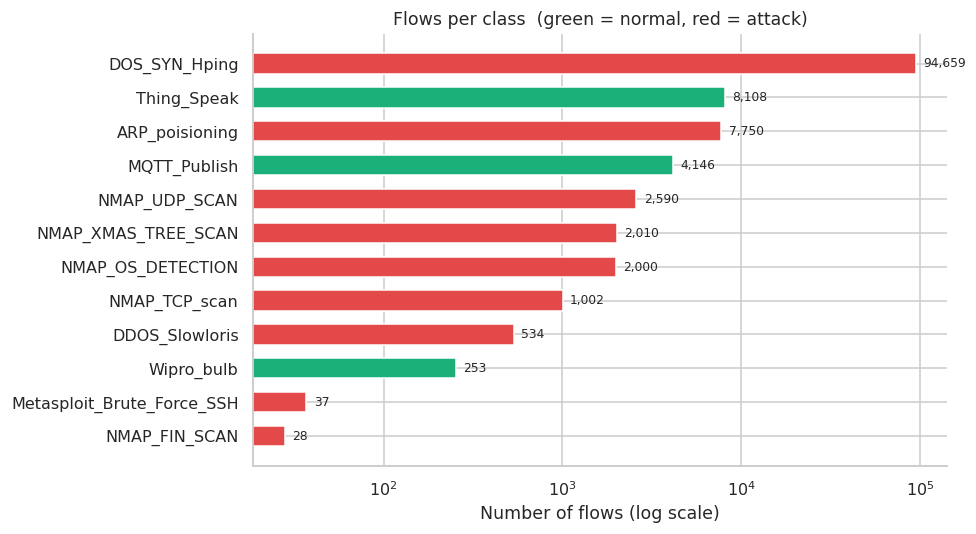

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#1baf7a" if c in NORMAL_CLASSES else "#e34948" for c in counts.index]
ax.barh(counts.index, counts.values, color=colors, height=0.6)
ax.set_xscale("log"); ax.invert_yaxis()
ax.set_xlabel("Number of flows (log scale)")
ax.set_title("Flows per class  (green = normal, red = attack)")
for i, v in enumerate(counts.values):
    ax.text(v * 1.1, i, f"{v:,}", va="center", fontsize=8)
save("01_class_distribution")

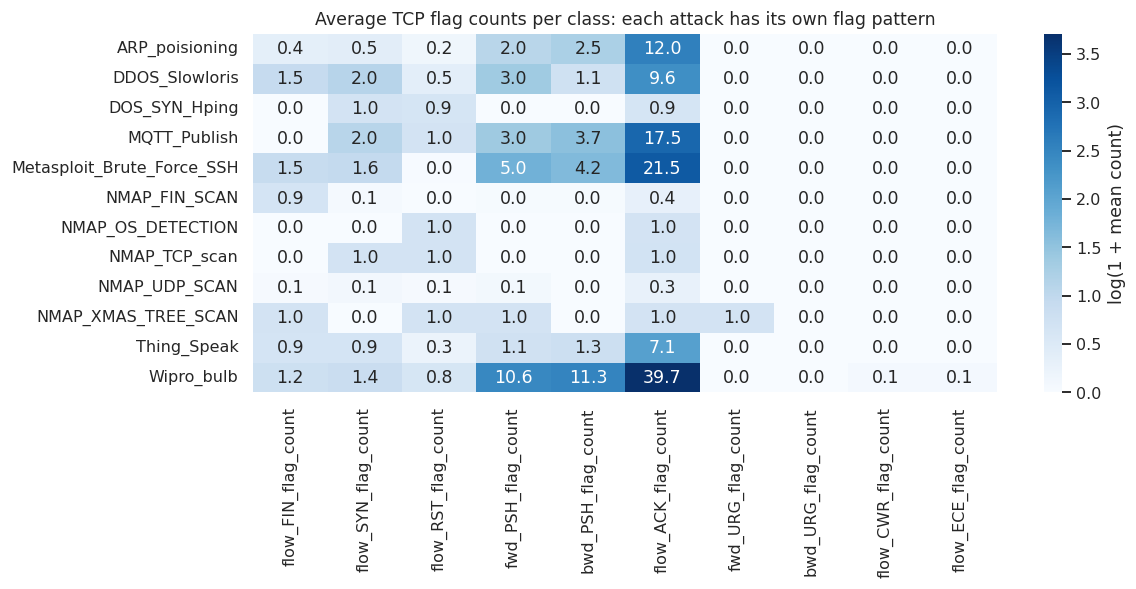

In [6]:
flag_cols = [c for c in df.columns if "flag_count" in c]
flag_mean = df.groupby(TARGET)[flag_cols].mean()
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(np.log1p(flag_mean), cmap="Blues", annot=flag_mean.round(1), fmt="", ax=ax,
            cbar_kws={"label": "log(1 + mean count)"})
ax.set_title("Average TCP flag counts per class: each attack has its own flag pattern")
ax.set_ylabel("")
save("02_tcp_flags_by_class")

**Observation (cybersecurity link):** each attack leaves a fingerprint in the TCP flags. The **XMAS scan** sets FIN+PSH+URG, the **FIN scan** sets only FIN, and the **SYN flood** sends SYN packets without completing the handshake. This is why an ML model can learn to recognise attacks from these features.

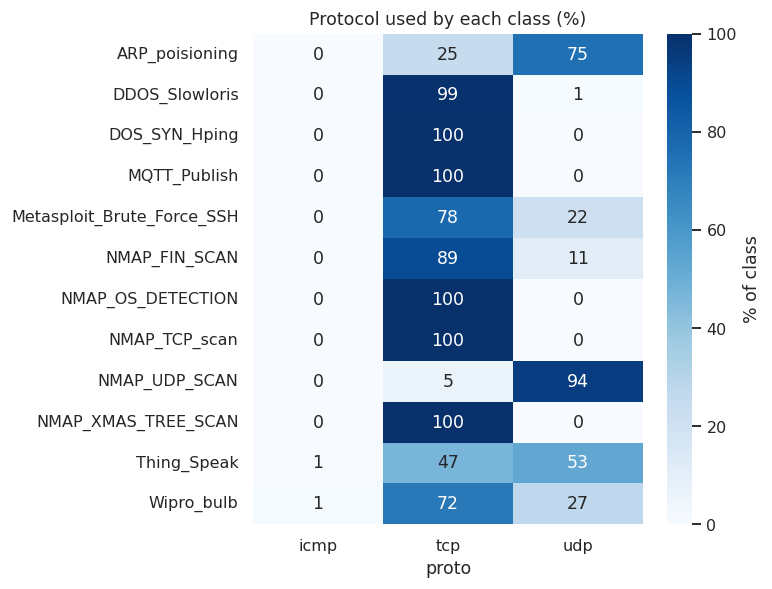

In [7]:
ct = pd.crosstab(df[TARGET], df["proto"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(ct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of class"}, ax=ax)
ax.set_title("Protocol used by each class (%)"); ax.set_ylabel("")
save("03_protocol_by_class")

## 5. Data preprocessing
1. **Drop `Unnamed: 0`** (row number) and the **port numbers** `id.orig_p`, `id.resp_p`. Ports only describe the lab setup, so the model should learn attack *behaviour* instead.
2. **Replace infinite / missing values** with 0.
3. **One-hot encode** the text columns `proto` and `service` (convert text to 0/1 numbers).
4. **Split 80% training / 20% testing** with *stratify* so every class appears in both sets.
5. **Remove constant features** and **highly correlated features (> 0.95)**, which carry no new information.

*Note:* Random Forest does not need feature scaling, because trees split on thresholds, not distances.

In [8]:
X = encode(basic_clean(df.drop(columns=[TARGET])))
y = df[TARGET]
print("Features after cleaning & encoding:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Training set:", X_train.shape, "  Testing set:", X_test.shape)

Features after cleaning & encoding: 92


Training set: (98493, 92)   Testing set: (24624, 92)


In [9]:
# Remove constant features (learned from training data only)
vt = VarianceThreshold(0.0).fit(X_train)
const_cols = X_train.columns[~vt.get_support()].tolist()
X_train, X_test = X_train.drop(columns=const_cols), X_test.drop(columns=const_cols)

# Remove one feature from each highly-correlated pair (> 0.95)
corr = X_train.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = [c for c in upper.columns if (upper[c] > 0.95).any()]
X_train, X_test = X_train.drop(columns=high_corr), X_test.drop(columns=high_corr)

FEATURES = X_train.columns.tolist()
print("Constant features removed      :", len(const_cols))
print("Correlated features removed    :", len(high_corr))
print("Final number of features used  :", len(FEATURES))

Constant features removed      : 1
Correlated features removed    : 19
Final number of features used  : 72


## 6. Train the Random Forest model
**How Random Forest works:** it builds many **decision trees**, each trained on a random sample of rows and features. Each tree votes for a class, and the **majority vote** is the final prediction. Combining many trees reduces overfitting and gives high accuracy.

**Settings used:**
| Parameter | Value | Meaning |
|---|---|---|
| `n_estimators` | 100 | number of trees |
| `class_weight` | `balanced_subsample` | gives rare attacks more weight (handles imbalance) |
| `random_state` | 42 | makes results reproducible |
| `n_jobs` | -1 | use all CPU cores |

In [10]:
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=RANDOM_STATE)
t0 = time.time()
rf.fit(X_train, y_train)
print(f"Training finished in {time.time() - t0:.1f} seconds")

Training finished in 3.9 seconds


## 7. Evaluate the model on the test set (data the model has never seen)
- **Accuracy**: % of flows classified correctly
- **Precision**: when the model says "attack X", how often it is right
- **Recall**: of all real "attack X" flows, how many it caught
- **F1-score**: balance of precision and recall; **macro-F1** averages all classes equally
- **Detection Rate**: % of all attacks detected (IDS metric)
- **False Alarm Rate**: % of normal flows wrongly flagged as attacks (IDS metric)

In [11]:
t0 = time.time()
y_pred = rf.predict(X_test)
pred_time = (time.time() - t0) / len(X_test) * 1e6

true_bin, pred_bin = y_test.apply(to_binary).values, pd.Series(y_pred).apply(to_binary).values
detection_rate  = ((true_bin == "Attack") & (pred_bin == "Attack")).sum() / (true_bin == "Attack").sum()
false_alarm_rate = ((true_bin == "Normal") & (pred_bin == "Attack")).sum() / (true_bin == "Normal").sum()

results = pd.DataFrame({"Value": [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred, average="macro"),
    recall_score(y_test, y_pred, average="macro"),
    f1_score(y_test, y_pred, average="macro"),
    f1_score(y_test, y_pred, average="weighted"),
    detection_rate, false_alarm_rate]},
    index=["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score",
           "Weighted F1-score", "Detection Rate", "False Alarm Rate"])
results["Value (%)"] = (results["Value"] * 100).round(2)
print(f"Prediction speed: {pred_time:.1f} microseconds per flow\n")
results.round(4)

Prediction speed: 4.4 microseconds per flow



,Value,Value (%)
Accuracy,0.9976,99.76
Macro Precision,0.9483,94.83
Macro Recall,0.9730,97.30
Macro F1-score,0.9590,95.90
Weighted F1-score,0.9976,99.76
Detection Rate,0.9996,99.96
False Alarm Rate,0.0104,1.04


In [12]:
print(classification_report(y_test, y_pred, digits=4))

                            precision    recall  f1-score   support

            ARP_poisioning     0.9840    0.9935    0.9888      1550
            DDOS_Slowloris     0.9604    0.9065    0.9327       107
             DOS_SYN_Hping     1.0000    1.0000    1.0000     18932
              MQTT_Publish     0.9988    0.9976    0.9982       829
Metasploit_Brute_Force_SSH     0.7778    1.0000    0.8750         7
             NMAP_FIN_SCAN     0.7143    0.8333    0.7692         6
         NMAP_OS_DETECTION     1.0000    1.0000    1.0000       400
             NMAP_TCP_scan     1.0000    1.0000    1.0000       200
             NMAP_UDP_SCAN     0.9714    0.9846    0.9779       518
       NMAP_XMAS_TREE_SCAN     0.9975    0.9950    0.9963       402
               Thing_Speak     0.9950    0.9846    0.9898      1622
                Wipro_bulb     0.9804    0.9804    0.9804        51

                  accuracy                         0.9976     24624
                 macro avg     0.9483    0.973

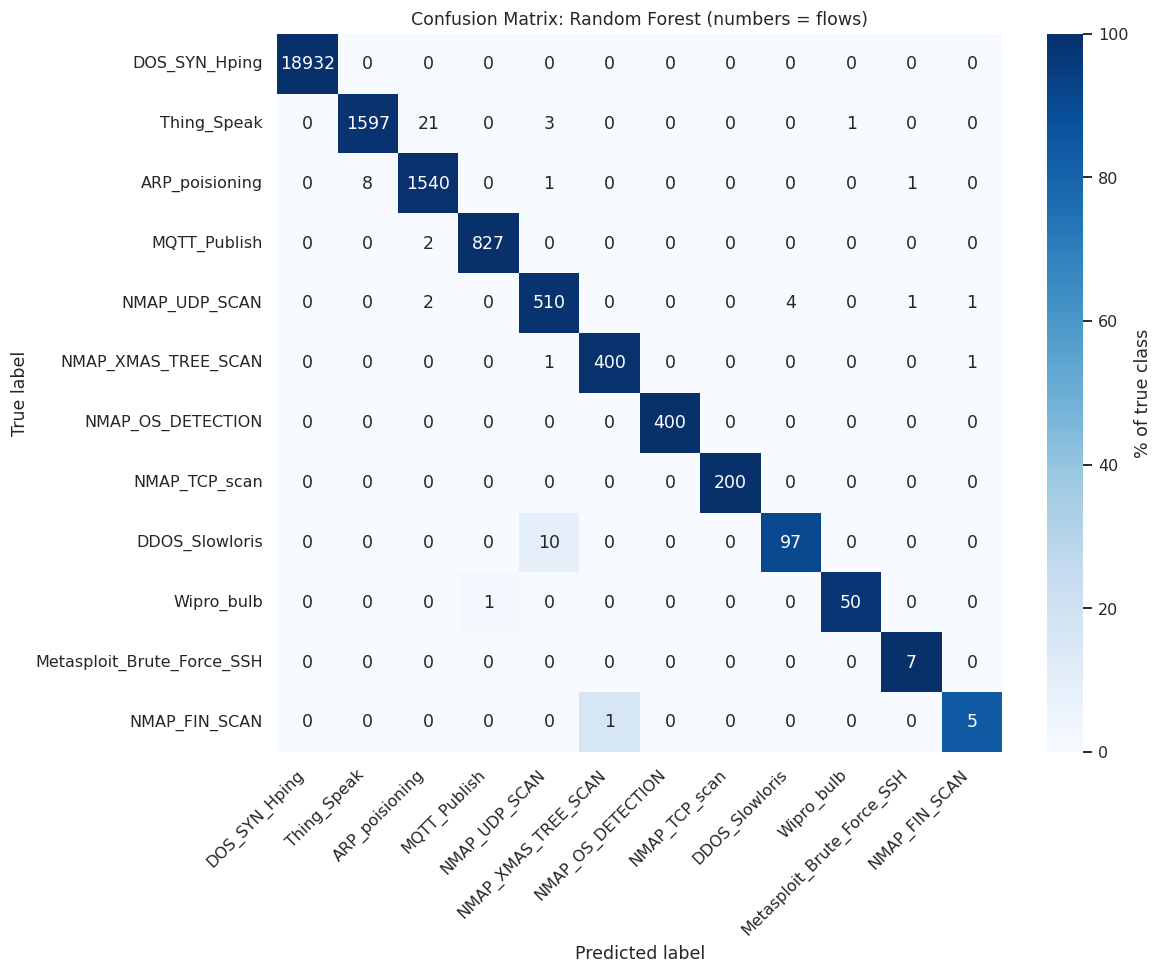

In [13]:
labels = counts.index.tolist()
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cm_pct, annot=cm, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels,
            cbar_kws={"label": "% of true class"}, ax=ax)
ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
ax.set_title("Confusion Matrix: Random Forest (numbers = flows)")
plt.xticks(rotation=45, ha="right")
save("04_confusion_matrix")

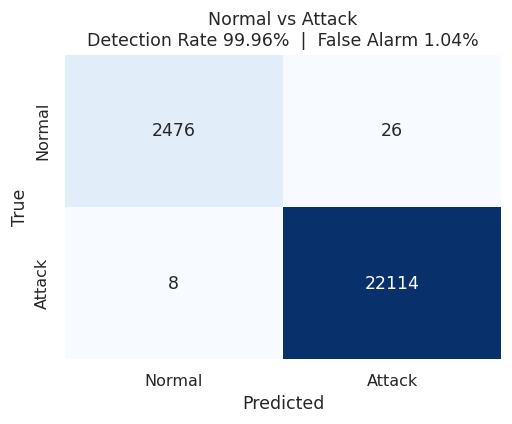

In [14]:
cmb = confusion_matrix(true_bin, pred_bin, labels=["Normal", "Attack"])
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cmb, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"], ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Normal vs Attack\nDetection Rate {detection_rate*100:.2f}%  |  False Alarm {false_alarm_rate*100:.2f}%")
save("05_confusion_matrix_binary")

**Observation:** almost all values lie on the diagonal (correct predictions). The few mistakes are between similar classes (e.g. a few Thing_Speak ↔ ARP_poisoning flows) and in the rarest attack classes, which have only 6–7 test samples.

## 8. 5-Fold Cross-Validation
To make sure the result is not luck from one particular split, we train and test the model **5 times** on different parts of the training data and average the score.

In [15]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                               n_jobs=-1, random_state=RANDOM_STATE)
cv_acc = cross_val_score(cv_rf, X_train, y_train, cv=skf, scoring="accuracy")
cv_f1  = cross_val_score(cv_rf, X_train, y_train, cv=skf, scoring="f1_macro")
print("Accuracy per fold :", np.round(cv_acc, 4))
print("Macro-F1 per fold :", np.round(cv_f1, 4))
print(f"\nMean accuracy = {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
print(f"Mean macro-F1 = {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")

Accuracy per fold : [0.9974 0.997  0.9962 0.9975 0.9971]
Macro-F1 per fold : [0.9513 0.9683 0.9518 0.9594 0.972 ]

Mean accuracy = 0.9970 ± 0.0004
Mean macro-F1 = 0.9606 ± 0.0084


## 9. Feature importance: which features does Random Forest use?
Random Forest measures how much each feature helps the trees split the data correctly.

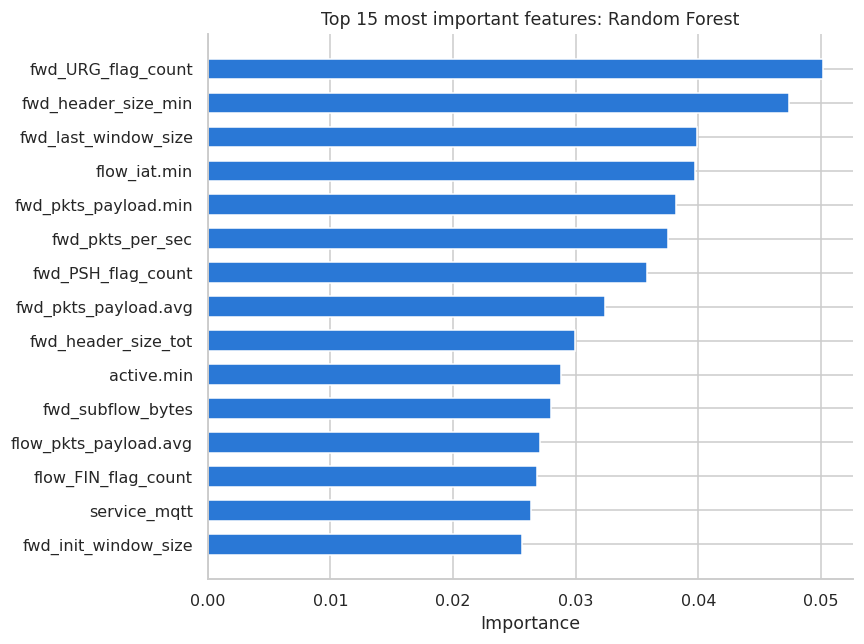

fwd_URG_flag_count       0.0501
fwd_header_size_min      0.0474
fwd_last_window_size     0.0399
flow_iat.min             0.0397
fwd_pkts_payload.min     0.0382
fwd_pkts_per_sec         0.0375
fwd_PSH_flag_count       0.0358
fwd_pkts_payload.avg     0.0324
fwd_header_size_tot      0.0300
active.min               0.0288
fwd_subflow_bytes        0.0280
flow_pkts_payload.avg    0.0271
flow_FIN_flag_count      0.0268
service_mqtt             0.0264
fwd_init_window_size     0.0256
dtype: float64

In [16]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color="#2a78d6", height=0.6)
ax.set_xlabel("Importance"); ax.set_title("Top 15 most important features: Random Forest")
save("06_feature_importance")
imp.head(15).round(4)

**Interpretation:** the most important features are TCP **window/header sizes**, **flag counts**, **packet rates / timing** and **payload sizes**. These match networking theory: attack tools craft packets with unusual flags and window sizes, floods have very high packet rates, and scans carry almost no payload. So the model is learning real attack behaviour.

## 10. Save the model and test it on new flows

In [17]:
joblib.dump({"model": rf, "features": FEATURES, "name": "Random Forest"}, "models/ids_random_forest.joblib")
print("Model saved to models/ids_random_forest.joblib")

# Load it back and predict unseen flows, like a real IDS would
bundle = joblib.load("models/ids_random_forest.joblib")
sample = X_test.groupby(y_test).sample(1, random_state=7)   # one unseen flow of each class
demo = pd.DataFrame({"True label": y_test.loc[sample.index].values,
                     "Predicted": bundle["model"].predict(sample[bundle["features"]])})
demo["Verdict"] = np.where(demo["Predicted"].isin(NORMAL_CLASSES), "Normal", "ATTACK")
demo["Correct?"] = np.where(demo["True label"] == demo["Predicted"], "Yes", "No")
demo

Model saved to models/ids_random_forest.joblib


,True label,Predicted,Verdict,Correct?
0,ARP_poisioning,ARP_poisioning,ATTACK,Yes
1,DDOS_Slowloris,DDOS_Slowloris,ATTACK,Yes
2,DOS_SYN_Hping,DOS_SYN_Hping,ATTACK,Yes
3,MQTT_Publish,MQTT_Publish,Normal,Yes
4,Metasploit_Brute_Force_SSH,Metasploit_Brute_Force_SSH,ATTACK,Yes
5,NMAP_FIN_SCAN,NMAP_FIN_SCAN,ATTACK,Yes
6,NMAP_OS_DETECTION,NMAP_OS_DETECTION,ATTACK,Yes
7,NMAP_TCP_scan,NMAP_TCP_scan,ATTACK,Yes
8,NMAP_UDP_SCAN,NMAP_UDP_SCAN,ATTACK,Yes
9,NMAP_XMAS_TREE_SCAN,NMAP_XMAS_TREE_SCAN,ATTACK,Yes


In [18]:
# Demo file for the Streamlit app: up to 40 unseen test flows per class
demo_df = df.loc[X_test.index].groupby(TARGET, group_keys=False).apply(
    lambda g: g.sample(min(len(g), 40), random_state=1))
demo_df.sample(frac=1, random_state=1).to_csv("data/demo_flows.csv", index=False)
print("Saved data/demo_flows.csv with", len(demo_df), "flows")

Saved data/demo_flows.csv with 413 flows


## 11. Conclusion
- We built an IoT Intrusion Detection System using a **Random Forest** classifier on the **RT-IoT2022** dataset (123,117 flows, 12 classes).
- The model classifies traffic into normal traffic or 9 attack types with **very high accuracy** and a **very low false alarm rate** on unseen test data (see Section 7).
- **5-fold cross-validation** confirms the result is stable.
- **Class weights** helped the model handle the heavy class imbalance.
- The most important features (TCP flags, window sizes, packet rates) match real attack behaviour, so the model is explainable.

**Limitations:** data from a single lab network; very few samples for FIN scan and SSH brute force.
**Future work:** test on other IoT datasets, deploy on an IoT gateway (e.g. Raspberry Pi) for real-time detection.